# DINOv2 Baseline Ablation Study Evaluation (Video-to-Video)

This notebook evaluates distance matrices generated by the ablation runs against the chosen **DINOv2 Baseline** on the DogReID-1553 closed-world video-to-video test set.

It computes and provides:
1. **mAP** (mean Average Precision) with 95% Bootstrap Confidence Intervals
2. **Rank-1, Rank-5, and Rank-10** Cumulative Matching Characteristic (CMC) with 95% Bootstrap Confidence Intervals
3. **Delta ($\Delta$) from Baseline** for Rank-1 and mAP to highlight relative gains/drops
4. **Categorized Breakdown Tables**:
   - **Backbone Adaptation Depth**: Frozen (0), 2, 4, 6 (Baseline), 8, 10, 12 blocks, and Full Fine-tuning
   - **Spatial & Multi-Layer Representation**: Pure `[CLS]` (Baseline), Patch Mean, Patch GeM, CLS+Mean, CLS+GeM, and Multi-Layer Fusion (`fuse4`)
   - **Feature Normalization & Neck**: BNNeck (Baseline) vs. No BNNeck (direct linear projection)
   - **Metric-Learning Objective**: Batch-Hard Triplet (Baseline), Soft Triplet, and Weighted Triplet
   - **Data Augmentation & Regularization**: RE + LS (Baseline), No RE, No LS, and AutoAugment
5. **Publication-Ready LaTeX Code Generator**: Pre-formatted tables directly pasteable into paper/appendix
6. **Visualizations**: Summary bar chart comparing all configurations against the baseline


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add root directory to sys.path
CURRENT_DIR = Path.cwd()
ROOT_DIR = CURRENT_DIR if (CURRENT_DIR / "evaluation").exists() else CURRENT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))
if str(ROOT_DIR / "evaluation") not in sys.path:
    sys.path.append(str(ROOT_DIR / "evaluation"))

from evaluation.evaluation_utils import bootstrap_from_csv

print("Loaded evaluation_utils successfully!")
print(f"Project root: {ROOT_DIR}")


Loaded evaluation_utils successfully!
Project root: /d/hpc/projects/FRI/mm12755/DogReID-1553/DogReID-1553


In [2]:
# =====================================================================
# Configuration: Ablation Registry & Discovery
# =====================================================================
ABLATIONS_DIR = ROOT_DIR / "evaluation" / "csvs_ablations"

ABLATION_METADATA = {
    # Baseline
    "baseline": {
        "category": "0. Baseline Reference",
        "display_name": "DINOv2 Baseline (Chosen)",
        "config_desc": "Unfreeze 6, [CLS], BNNeck, Batch-Hard, RE (0.5), LS (0.1), Cosine",
        "order": 0
    },
    # 1. Depth
    "unfreeze0": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Frozen Backbone (0 blocks)",
        "config_desc": "Only temporal pooling + BNNeck trained",
        "order": 10
    },
    "unfreeze2": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 2 blocks",
        "config_desc": "Blocks 10-11 unfrozen",
        "order": 11
    },
    "unfreeze4": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 4 blocks",
        "config_desc": "Blocks 8-11 unfrozen",
        "order": 12
    },
    "unfreeze6": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 6 blocks (Baseline)",
        "config_desc": "Blocks 6-11 unfrozen",
        "order": 13
    },
    "unfreeze8": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 8 blocks",
        "config_desc": "Blocks 4-11 unfrozen",
        "order": 14
    },
    "unfreeze10": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 10 blocks",
        "config_desc": "Blocks 2-11 unfrozen",
        "order": 15
    },
    "unfreeze12": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Unfreeze 12 blocks",
        "config_desc": "All 12 transformer blocks unfrozen",
        "order": 16
    },
    "full_finetune": {
        "category": "1. Backbone Adaptation Depth",
        "display_name": "Full Fine-tune",
        "config_desc": "All blocks + patch embed + final norm unfrozen",
        "order": 17
    },
    # 2. Token / Layer Representation
    "cls": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "Pure [CLS] Token (Baseline)",
        "config_desc": "Final layer [CLS] token representation",
        "order": 20
    },
    "patch_mean": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "Patch Mean Pooling",
        "config_desc": "Mean across spatial patch tokens",
        "order": 21
    },
    "patch_gem": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "Patch GeM Pooling",
        "config_desc": "Generalized mean pooling (p=3.0) on patch tokens",
        "order": 22
    },
    "cls_mean": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "CLS + Patch Mean",
        "config_desc": "Concatenation of CLS token and patch mean",
        "order": 23
    },
    "cls_gem": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "CLS + Patch GeM",
        "config_desc": "Concatenation of CLS token and patch GeM",
        "order": 24
    },
    "fuse4": {
        "category": "2. Spatial & Multi-Layer Representation",
        "display_name": "Multi-Layer Fusion (fuse4)",
        "config_desc": "Softmax-weighted fusion across blocks 8-11",
        "order": 25
    },
    # 3. Normalization & Neck
    "bnneck": {
        "category": "3. Feature Normalization & Neck",
        "display_name": "BNNeck (Baseline)",
        "config_desc": "Linear projection + BatchNorm1d neck",
        "order": 30
    },
    "no_bnneck": {
        "category": "3. Feature Normalization & Neck",
        "display_name": "No BNNeck",
        "config_desc": "Direct linear projection without BatchNorm neck",
        "order": 31
    },
    # 4. Metric Loss
    "batch_hard": {
        "category": "4. Metric-Learning Objective",
        "display_name": "Batch-Hard Triplet (Baseline)",
        "config_desc": "Hard Euclidean triplet loss (margin = 0.3)",
        "order": 40
    },
    "soft_triplet": {
        "category": "4. Metric-Learning Objective",
        "display_name": "Soft Triplet Loss",
        "config_desc": "Smooth soft-margin triplet loss without fixed margin",
        "order": 41
    },
    "weighted_triplet": {
        "category": "4. Metric-Learning Objective",
        "display_name": "Weighted Triplet Loss",
        "config_desc": "Distance-weighted batch triplet loss",
        "order": 42
    },
    # 5. Regularization & Augmentation
    "standard_aug": {
        "category": "5. Data Augmentation & Regularization",
        "display_name": "RE + LS (Baseline)",
        "config_desc": "Random Erasing (p=0.5) + Label Smoothing (0.1)",
        "order": 50
    },
    "no_re": {
        "category": "5. Data Augmentation & Regularization",
        "display_name": "No Random Erasing",
        "config_desc": "Random Erasing probability p = 0.0",
        "order": 51
    },
    "no_ls": {
        "category": "5. Data Augmentation & Regularization",
        "display_name": "No Label Smoothing",
        "config_desc": "Standard cross-entropy (epsilon = 0.0)",
        "order": 52
    },
    "autoaug": {
        "category": "5. Data Augmentation & Regularization",
        "display_name": "AutoAugment (SBS)",
        "config_desc": "ImageNet AutoAugment policy (p=0.1)",
        "order": 53
    },
    # 6. Temporal Aggregation
    "temporal_mean": {
        "category": "6. Temporal Aggregation",
        "display_name": "Temporal Mean Pooling",
        "config_desc": "Simple average pooling across 8 frames instead of attention",
        "order": 60
    },
    "temporal_max": {
        "category": "6. Temporal Aggregation",
        "display_name": "Temporal Max Pooling",
        "config_desc": "Element-wise max pooling across 8 frames instead of attention",
        "order": 61
    }
}

discovered_ablations = {}
if ABLATIONS_DIR.exists():
    for p in sorted(ABLATIONS_DIR.iterdir()):
        if not p.is_dir():
            continue
        key = p.name.replace("_vid2vid", "").replace("_img2vid", "")
        if key in ("clip_backbone", "clip_baseline", "clip") or key.startswith("og_") or key.startswith("backup"):
            continue
        csv_candidates = list(p.glob("*closed*.csv")) + list(p.glob("*.csv"))
        for c in csv_candidates:
            if c.stat().st_size > 1000:
                meta = ABLATION_METADATA.get(key, {
                    "category": "6. Other Ablations",
                    "display_name": key.replace("_", " ").title(),
                    "config_desc": p.name,
                    "order": 99
                })
                discovered_ablations[key] = {
                    "key": key,
                    "folder": p.name,
                    "csv_path": c,
                    **meta
                }
                break

print(f"Total ablation directories discovered with valid CSVs: {len(discovered_ablations)}")
print("-" * 80)
for k, v in discovered_ablations.items():
    cat = v['category']
    disp = v['display_name']
    rel_path = v['csv_path'].relative_to(ROOT_DIR)
    print(f"[{cat}] {disp:<30} -> {rel_path}")


Total ablation directories discovered with valid CSVs: 21
--------------------------------------------------------------------------------
[6. Other Ablations] Agw                            -> evaluation/csvs_ablations/agw_vid2vid/closed_dist_matrix.csv
[5. Data Augmentation & Regularization] AutoAugment (SBS)              -> evaluation/csvs_ablations/autoaug_vid2vid/closed_dist_matrix.csv
[0. Baseline Reference] DINOv2 Baseline (Chosen)       -> evaluation/csvs_ablations/baseline_vid2vid/closed_dist_matrix.csv
[2. Spatial & Multi-Layer Representation] CLS + Patch GeM                -> evaluation/csvs_ablations/cls_gem_vid2vid/closed_dist_matrix.csv
[2. Spatial & Multi-Layer Representation] CLS + Patch Mean               -> evaluation/csvs_ablations/cls_mean_vid2vid/closed_dist_matrix.csv
[1. Backbone Adaptation Depth] Full Fine-tune                 -> evaluation/csvs_ablations/full_finetune_vid2vid/closed_dist_matrix.csv
[2. Spatial & Multi-Layer Representation] Multi-Layer Fusion (f

In [3]:
# =====================================================================
# Run Bootstrap Evaluation on Available CSVs
# =====================================================================
M_ITERATIONS = 100  # Number of bootstrap resamples for 95% Confidence Intervals
all_ablation_results = {}

for key, item in discovered_ablations.items():
    csv_file = item["csv_path"]
    disp_name = item["display_name"]
    print("=" * 70)
    print(f"Evaluating {disp_name} ({key}) from {csv_file.name} ...")
    print("=" * 70)
    try:
        res = bootstrap_from_csv(str(csv_file), m=M_ITERATIONS, mode="closed")
        all_ablation_results[key] = {
            "meta": item,
            "metrics": res
        }
    except Exception as e:
        print(f"[ERROR] Failed to evaluate {key}: {e}")

print(f"\n[DONE] Successfully evaluated {len(all_ablation_results)} ablations!")


Evaluating Agw (agw) from closed_dist_matrix.csv ...
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
Evaluating AutoAugment (SBS) (autoaug) from closed_dist_matrix.csv ...
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
Evaluating DINOv2 Baseline (Chosen) (baseline) from closed_dist_matrix.csv ...
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
Evaluating CLS + Patch GeM (cls_gem) from closed_dist_matrix.csv ...
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
Evaluating CLS + Patch Mean (cls_mean) from closed_dist_matrix.csv ...
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
Evaluating Full Fine-tune (full_finetune) from 

In [4]:
# =====================================================================
# Full Results Table (with Baseline comparison & deltas)
# =====================================================================
rows = []

# Baseline reference metrics for delta calculation
base_res = all_ablation_results.get("baseline", {}).get("metrics", {})
base_mAP = base_res.get("mAP_boot_mean", None)
base_cmc = base_res.get("cmc_boot_mean", None)
base_r1 = base_cmc[0] if base_cmc is not None and len(base_cmc) > 0 else None

for key, entry in all_ablation_results.items():
    meta = entry["meta"]
    res = entry["metrics"]
    full = res.get("full_set", {})
    
    # mAP
    m_mean = res.get("mAP_boot_mean", full.get("mAP", 0.0)) * 100
    m_std = res.get("mAP_std", 0.0) * 100
    m_ci = res.get("mAP_ci", (0.0, 0.0))
    m_low, m_high = m_ci[0] * 100, m_ci[1] * 100
    
    # CMC Rank-1, Rank-5, Rank-10
    cmc_boot = res.get("cmc_boot_mean", full.get("cmc", np.zeros(10)))
    cmc_std = res.get("cmc_std", np.zeros(10))
    cmc_l = res.get("cmc_ci_lower", cmc_boot)
    cmc_u = res.get("cmc_ci_upper", cmc_boot)
    
    r1 = cmc_boot[0] * 100
    r1_std = cmc_std[0] * 100 if len(cmc_std) > 0 else 0.0
    r1_l, r1_u = cmc_l[0] * 100, cmc_u[0] * 100
    
    r5 = cmc_boot[4] * 100 if len(cmc_boot) >= 5 else 0.0
    r5_std = cmc_std[4] * 100 if len(cmc_std) >= 5 else 0.0
    r5_l = cmc_l[4] * 100 if len(cmc_l) >= 5 else 0.0
    r5_u = cmc_u[4] * 100 if len(cmc_u) >= 5 else 0.0
    
    r10 = cmc_boot[9] * 100 if len(cmc_boot) >= 10 else 0.0
    r10_l, r10_u = cmc_l[9] * 100, cmc_u[9] * 100
    
    # Deltas
    delta_r1 = (r1 - base_r1 * 100) if base_r1 is not None else 0.0
    delta_map = (m_mean - base_mAP * 100) if base_mAP is not None else 0.0
    delta_str = f"{delta_r1:+.1f} / {delta_map:+.1f}" if key != "baseline" else "Reference"
    
    rows.append({
        "Key": key,
        "Order": meta.get("order", 99),
        "Category": meta.get("category", "Other"),
        "Variant": meta.get("display_name", key),
        "Description": meta.get("config_desc", ""),
        "Rank-1 (%) [95% CI]": f"{r1:.1f} ± {r1_std:.1f} [{r1_l:.1f}-{r1_u:.1f}]",
        "Rank-5 (%) [95% CI]": f"{r5:.1f} ± {r5_std:.1f} [{r5_l:.1f}-{r5_u:.1f}]",
        "mAP (%) [95% CI]": f"{m_mean:.1f} ± {m_std:.1f} [{m_low:.1f}-{m_high:.1f}]",
        "Δ R-1 / Δ mAP": delta_str,
        "Rank-1_raw": r1,
        "mAP_raw": m_mean,
        "Rank-5_raw": r5
    })

df_all = pd.DataFrame(rows).sort_values("Order").reset_index(drop=True)

hdr_var = "Variant"
hdr_r1 = "Rank-1 [95% CI]"
hdr_map = "mAP [95% CI]"
hdr_delta = "Δ (R-1/mAP)"
hdr_cat = "Category"

print("=" * 120)
print(f"{hdr_var:<30} | {hdr_r1:<24} | {hdr_map:<24} | {hdr_delta:<14} | {hdr_cat}")
print("=" * 120)
for _, r in df_all.iterrows():
    v = r["Variant"]
    r1_s = r["Rank-1 (%) [95% CI]"]
    map_s = r["mAP (%) [95% CI]"]
    d_s = r["Δ R-1 / Δ mAP"]
    c_s = r["Category"]
    print(f"{v:<30} | {r1_s:<24} | {map_s:<24} | {d_s:<14} | {c_s}")
print("-" * 120)

display_cols = ["Category", "Variant", "Rank-1 (%) [95% CI]", "mAP (%) [95% CI]", "Rank-5 (%) [95% CI]", "Δ R-1 / Δ mAP", "Description"]
df_all[display_cols]


Variant                        | Rank-1 [95% CI]          | mAP [95% CI]             | Δ (R-1/mAP)    | Category
DINOv2 Baseline (Chosen)       | 61.3 ± 1.5 [58.5-64.2]   | 57.6 ± 1.1 [55.6-59.9]   | Reference      | 0. Baseline Reference
Frozen Backbone (0 blocks)     | 43.6 ± 1.6 [40.7-46.3]   | 41.7 ± 1.2 [39.6-43.9]   | -17.7 / -15.9  | 1. Backbone Adaptation Depth
Unfreeze 2 blocks              | 61.9 ± 1.5 [59.0-64.6]   | 58.0 ± 1.1 [56.0-60.4]   | +0.6 / +0.4    | 1. Backbone Adaptation Depth
Unfreeze 4 blocks              | 61.8 ± 1.4 [59.1-64.8]   | 58.1 ± 1.1 [56.1-60.4]   | +0.5 / +0.5    | 1. Backbone Adaptation Depth
Unfreeze 8 blocks              | 61.3 ± 1.5 [58.4-64.3]   | 58.2 ± 1.2 [56.0-60.6]   | +0.0 / +0.6    | 1. Backbone Adaptation Depth
Unfreeze 10 blocks             | 61.6 ± 1.4 [59.1-64.7]   | 57.5 ± 1.1 [55.6-60.0]   | +0.3 / -0.2    | 1. Backbone Adaptation Depth
Full Fine-tune                 | 60.5 ± 1.5 [57.8-63.3]   | 56.6 ± 1.2 [54.4-59.2]   | -0.8 / -1

,Category,Variant,Rank-1 (%) [95% CI],mAP (%) [95% CI],Rank-5 (%) [95% CI],Δ R-1 / Δ mAP,Description
0,0. Baseline Reference,DINOv2 Baseline (Chosen),61.3 ± 1.5 [58.5-64.2],57.6 ± 1.1 [55.6-59.9],79.6 ± 1.2 [77.2-81.7],Reference,"Unfreeze 6, [CLS], BNNeck, Batch-Hard, RE (0.5), LS (0.1), Cosine"
1,1. Backbone Adaptation Depth,Frozen Backbone (0 blocks),43.6 ± 1.6 [40.7-46.3],41.7 ± 1.2 [39.6-43.9],66.0 ± 1.5 [63.0-68.8],-17.7 / -15.9,Only temporal pooling + BNNeck trained
2,1. Backbone Adaptation Depth,Unfreeze 2 blocks,61.9 ± 1.5 [59.0-64.6],58.0 ± 1.1 [56.0-60.4],79.6 ± 1.2 [76.9-82.0],+0.6 / +0.4,Blocks 10-11 unfrozen
3,1. Backbone Adaptation Depth,Unfreeze 4 blocks,61.8 ± 1.4 [59.1-64.8],58.1 ± 1.1 [56.1-60.4],79.2 ± 1.1 [76.7-81.6],+0.5 / +0.5,Blocks 8-11 unfrozen
4,1. Backbone Adaptation Depth,Unfreeze 8 blocks,61.3 ± 1.5 [58.4-64.3],58.2 ± 1.2 [56.0-60.6],79.5 ± 1.2 [77.0-81.9],+0.0 / +0.6,Blocks 4-11 unfrozen
5,1. Backbone Adaptation Depth,Unfreeze 10 blocks,61.6 ± 1.4 [59.1-64.7],57.5 ± 1.1 [55.6-60.0],78.9 ± 1.2 [76.8-81.3],+0.3 / -0.2,Blocks 2-11 unfrozen
6,1. Backbone Adaptation Depth,Full Fine-tune,60.5 ± 1.5 [57.8-63.3],56.6 ± 1.2 [54.4-59.2],79.0 ± 1.3 [76.7-81.6],-0.8 / -1.0,All blocks + patch embed + final norm unfrozen
7,2. Spatial & Multi-Layer Representation,Patch Mean Pooling,58.6 ± 1.5 [55.5-61.3],55.5 ± 1.1 [53.5-57.9],77.2 ± 1.2 [74.8-79.6],-2.7 / -2.1,Mean across spatial patch tokens
8,2. Spatial & Multi-Layer Representation,Patch GeM Pooling,57.7 ± 1.5 [54.8-60.6],54.1 ± 1.2 [51.9-56.5],75.7 ± 1.4 [73.4-78.3],-3.6 / -3.5,Generalized mean pooling (p=3.0) on patch tokens
9,2. Spatial & Multi-Layer Representation,CLS + Patch Mean,61.7 ± 1.5 [59.2-64.2],58.1 ± 1.1 [56.0-60.4],79.6 ± 1.2 [77.4-81.7],+0.4 / +0.5,Concatenation of CLS token and patch mean


## Backbone Adaptation Depth Scaling (Rank-1 & mAP with 95% Confidence Intervals)

This plot visualizes how performance scales as transformer blocks are progressively unfrozen,
from completely frozen (0 blocks) up to full backbone fine-tuning, including 95% bootstrap confidence intervals.


-> Saved figure to /d/hpc/projects/FRI/mm12755/DogReID-1553/DogReID-1553/evaluation/figures/unfreezing_stages_scaling.png


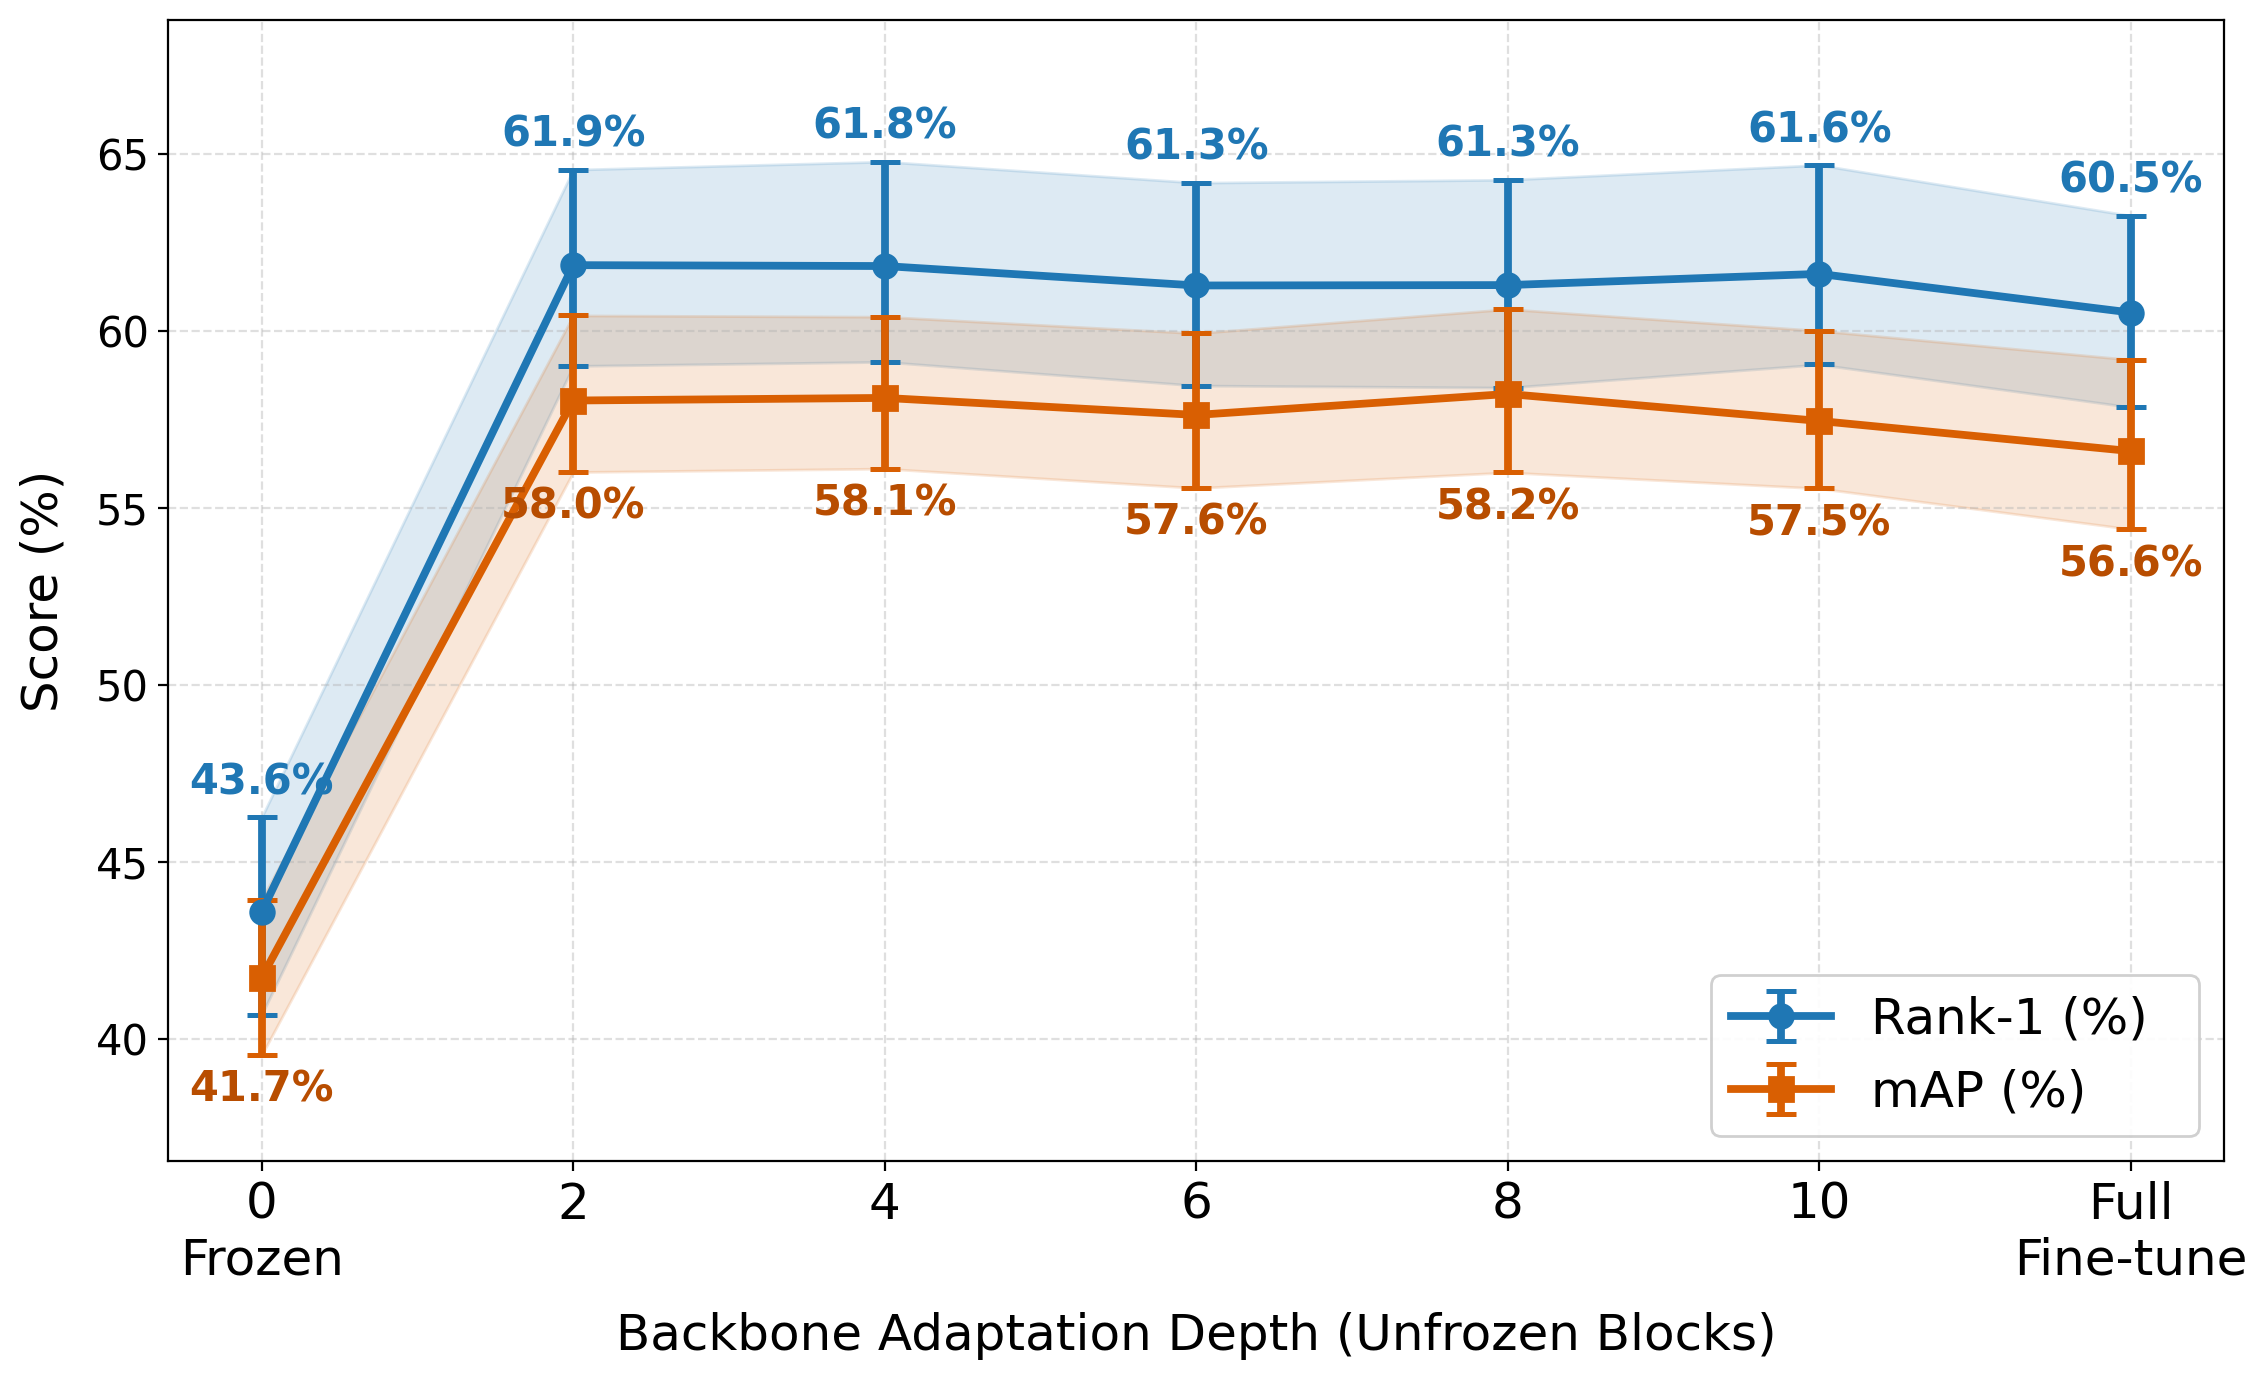

In [6]:
# =====================================================================
# Plot: Performance vs. Backbone Adaptation Depth (with 95% Bootstrap CIs)
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Ordered list of candidate depth stages
depth_stage_defs = [
    {"keys": ["unfreeze0"], "label": "0\nFrozen", "short": "0"},
    {"keys": ["unfreeze2"], "label": "2", "short": "2"},
    {"keys": ["unfreeze4"], "label": "4", "short": "4"},
    {"keys": ["baseline", "unfreeze6"], "label": "6", "short": "6", "is_base": True},
    {"keys": ["unfreeze8"], "label": "8", "short": "8"},
    {"keys": ["unfreeze10"], "label": "10", "short": "10"},
    {"keys": ["full_finetune"], "label": "Full\nFine-tune", "short": "Full FT"},
]

plot_stages = []
for stage in depth_stage_defs:
    for k in stage["keys"]:
        if k in all_ablation_results:
            res = all_ablation_results[k]["metrics"]
            full = res.get("full_set", {})
            
            cmc_boot = res.get("cmc_boot_mean", full.get("cmc", np.zeros(10)))
            cmc_l = res.get("cmc_ci_lower", cmc_boot)
            cmc_u = res.get("cmc_ci_upper", cmc_boot)
            r1 = cmc_boot[0] * 100
            r1_l, r1_u = cmc_l[0] * 100, cmc_u[0] * 100
            
            m_mean = res.get("mAP_boot_mean", full.get("mAP", 0.0)) * 100
            m_ci = res.get("mAP_ci", (0.0, 0.0))
            m_l, m_u = m_ci[0] * 100, m_ci[1] * 100
            
            plot_stages.append({
                "key": k,
                "label": stage["label"],
                "short": stage["short"],
                "is_base": stage.get("is_base", False),
                "r1": r1,
                "r1_l": r1_l,
                "r1_u": r1_u,
                "map": m_mean,
                "map_l": m_l,
                "map_u": m_u,
            })
            break

if len(plot_stages) >= 2:
    fig, ax = plt.subplots(figsize=(11.5, 7.0), dpi=200)
    x_indices = np.arange(len(plot_stages))
    labels = [s["label"] for s in plot_stages]
    
    r1_vals = np.array([s["r1"] for s in plot_stages])
    r1_lows = np.array([s["r1_l"] for s in plot_stages])
    r1_highs = np.array([s["r1_u"] for s in plot_stages])
    
    map_vals = np.array([s["map"] for s in plot_stages])
    map_lows = np.array([s["map_l"] for s in plot_stages])
    map_highs = np.array([s["map_u"] for s in plot_stages])
    
    # Shaded 95% Confidence Interval bands
    ax.fill_between(x_indices, r1_lows, r1_highs, color="#1f77b4", alpha=0.15, label="_nolegend_")
    ax.fill_between(x_indices, map_lows, map_highs, color="#d95f02", alpha=0.15, label="_nolegend_")
    
    # Curves with error bars
    ax.errorbar(x_indices, r1_vals, yerr=[r1_vals - r1_lows, r1_highs - r1_vals],
                fmt="-o", color="#1f77b4", label="Rank-1 (%)  ",
                linewidth=2.8, markersize=8.5, capsize=5.5, capthick=1.8)
    
    ax.errorbar(x_indices, map_vals, yerr=[map_vals - map_lows, map_highs - map_vals],
                fmt="-s", color="#d95f02", label="mAP (%)  ",
                linewidth=2.8, markersize=8.5, capsize=5.5, capthick=1.8)
    
    # Annotate values just outside the confidence intervals
    for i, s in enumerate(plot_stages):
        ax.annotate(
            f"{s['r1']:.1f}%",
            xy=(i, s["r1_u"]),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=15,
            color="#1f77b4",
            weight="bold",
        )

        ax.annotate(
            f"{s['map']:.1f}%",
            xy=(i, s["map_l"]),
            xytext=(0, -5),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=15,
            color="#b84d00",
            weight="bold",
        )
    
    ax.set_xticks(x_indices)
    ax.set_xticklabels(labels, fontsize=18)
    ax.tick_params(axis="y", labelsize=15)
    ax.set_xlabel("Backbone Adaptation Depth (Unfrozen Blocks)", fontsize=18, labelpad=10)
    ax.set_ylabel("Score (%)", fontsize=18, labelpad=10)
    ax.grid(True, linestyle="--", alpha=0.4)
    
    # Dynamic y-limit with breathing room
    y_min = max(0.0, min(map_lows) - 3.0)
    y_max = min(100.0, max(r1_highs) + 4.0)
    ax.set_ylim(y_min, y_max)
    
    ax.legend(loc="lower right", framealpha=0.92, fontsize=18)
    plt.tight_layout()
    
    # Save publication figure
    fig_dir = ROOT_DIR / "evaluation" / "figures"
    fig_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(fig_dir / "unfreezing_stages_scaling.png", dpi=300, bbox_inches="tight")
    plt.savefig(fig_dir / "unfreezing_stages_scaling.pdf", bbox_inches="tight")
    print("-> Saved figure to " + str(fig_dir / "unfreezing_stages_scaling.png"))
    plt.show()
else:
    print("[INFO] Insufficient depth stages discovered yet to render curve plot.")

## Diagnostic Evaluations (Subject Masking & Number of Frames)

Evaluation of the DINOv2 baseline under:
1. **Subject Masking & Crop Quality**: V2V background-only masking, and I2V queries with YOLO crop, GT crop, YOLO-masked, and GT-masked.
2. **Number of Frames**: Inference across 4, 8 (baseline), 16, and 32 frames with dynamic temporal attention pooling.

In [8]:
# =====================================================================
# Diagnostic Evaluations: Masking & Number of Frames Tables
# =====================================================================
DIAG_DIR = ROOT_DIR / "evaluation" / "csvs_diagnostics"
CLOSED_DIR = ROOT_DIR / "evaluation" / "csvs_closed_results"

def get_row(name, path, fallback_path=None, ref_r1=None, ref_map=None):
    p = path if path.exists() and path.stat().st_size > 0 else (fallback_path if fallback_path and fallback_path.exists() else None)
    if not p:
        return {"Setting": name, "Rank-1 (%) [95% CI]": "Pending...", "mAP (%) [95% CI]": "Pending...", "Δ (R-1 / mAP)": "-"}
    res = bootstrap_from_csv(str(p), m=100, mode="closed")
    m_mean = res.get("mAP_boot_mean", 0.0) * 100
    m_std = res.get("mAP_std", 0.0) * 100
    m_ci = res.get("mAP_ci", (0.0, 0.0))
    cmc_boot = res.get("cmc_boot_mean", [0.0]*10)
    cmc_std = res.get("cmc_std", np.zeros(10))
    cmc_l = res.get("cmc_ci_lower", cmc_boot)
    cmc_u = res.get("cmc_ci_upper", cmc_boot)
    cmc = cmc_boot[0] * 100
    r1_std = cmc_std[0] * 100 if len(cmc_std) > 0 else 0.0
    cmc_ci = (cmc_l[0] * 100, cmc_u[0] * 100)
    r5 = cmc_boot[4] * 100 if len(cmc_boot) >= 5 else 0.0
    r5_std = cmc_std[4] * 100 if len(cmc_std) >= 5 else 0.0
    r5_ci = (cmc_l[4] * 100, cmc_u[4] * 100) if len(cmc_l) >= 5 else (r5, r5)
    delta = "Reference" if ref_r1 is None else f"{(cmc - ref_r1):+.1f} / {(m_mean - ref_map):+.1f}"
    return {
        "Setting": name,
        "Rank-1 (%) [95% CI]": f"{cmc:.1f} ± {r1_std:.1f} [{cmc_ci[0]:.1f}-{cmc_ci[1]:.1f}]",
        "Rank-5 (%) [95% CI]": f"{r5:.1f} ± {r5_std:.1f} [{r5_ci[0]:.1f}-{r5_ci[1]:.1f}]",
        "mAP (%) [95% CI]": f"{m_mean:.1f} ± {m_std:.1f} [{m_ci[0]*100:.1f}-{m_ci[1]*100:.1f}]",
        "Δ (R-1 / mAP)": delta,
        "_r1": cmc, "_r5": r5, "_map": m_mean
    }

# 1. Subject Masking & Crop Quality
base_v2v = get_row("V2V Standard (Unmasked)", CLOSED_DIR / "baseline_vid2vid" / "closed_dist_matrix.csv", ROOT_DIR / "evaluation/csvs_ablations/baseline/closed_dist_matrix.csv")
v2v_r1, v2v_map = base_v2v.get("_r1"), base_v2v.get("_map")

base_i2v = get_row("I2V Standard (YOLO Crop, Unmasked)", DIAG_DIR / "baseline_img2vid_unmasked_yolo" / "closed_dist_matrix.csv", CLOSED_DIR / "baseline_img2vid" / "closed_dist_matrix.csv")
i2v_r1, i2v_map = base_i2v.get("_r1"), base_i2v.get("_map")

masking_rows = [
    base_v2v,
    get_row("V2V YOLO-Masked (Background-Only)", DIAG_DIR / "baseline_vid2vid_masked" / "closed_dist_matrix.csv", ref_r1=v2v_r1, ref_map=v2v_map),
    base_i2v,
    get_row("I2V GT Crop (Unmasked)", DIAG_DIR / "baseline_img2vid_unmasked_gt" / "closed_dist_matrix.csv", DIAG_DIR / "baseline_img2vid_gt_query" / "closed_dist_matrix.csv", ref_r1=i2v_r1, ref_map=i2v_map),
    get_row("I2V YOLO-Masked Query", DIAG_DIR / "baseline_img2vid_masked_yolo" / "closed_dist_matrix.csv", ref_r1=i2v_r1, ref_map=i2v_map),
    get_row("I2V GT-Masked Query", DIAG_DIR / "baseline_img2vid_masked_gt" / "closed_dist_matrix.csv", ref_r1=i2v_r1, ref_map=i2v_map),
]
df_masking = pd.DataFrame(masking_rows)[["Setting", "Rank-1 (%) [95% CI]", "Rank-5 (%) [95% CI]", "mAP (%) [95% CI]", "Δ (R-1 / mAP)"]]

print("=== Subject Masking & Crop Quality Diagnostic ===")
display(df_masking)

-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
=== Subject Masking & Crop Quality Diagnostic ===


,Setting,Rank-1 (%) [95% CI],Rank-5 (%) [95% CI],mAP (%) [95% CI],Δ (R-1 / mAP)
0,V2V Standard (Unmasked),61.3 ± 1.5 [58.5-64.2],79.6 ± 1.2 [77.2-81.7],57.6 ± 1.1 [55.6-59.9],Reference
1,V2V YOLO-Masked (Background-Only),17.1 ± 1.1 [14.9-19.0],31.9 ± 1.3 [29.3-34.5],16.3 ± 0.8 [14.9-17.8],-44.1 / -41.3
2,"I2V Standard (YOLO Crop, Unmasked)",51.5 ± 1.4 [48.8-54.6],71.7 ± 1.3 [69.4-74.2],50.0 ± 1.1 [47.9-52.2],Reference
3,I2V GT Crop (Unmasked),53.9 ± 1.5 [51.4-57.3],76.5 ± 1.2 [74.2-78.9],52.8 ± 1.1 [50.9-55.3],+2.4 / +2.8
4,I2V YOLO-Masked Query,6.5 ± 0.6 [5.3-7.8],12.4 ± 0.9 [11.0-14.1],6.5 ± 0.4 [5.8-7.4],-45.0 / -43.4
5,I2V GT-Masked Query,0.2 ± 0.1 [0.0-0.4],2.0 ± 0.3 [1.4-2.7],1.0 ± 0.1 [0.9-1.2],-51.3 / -48.9


In [9]:
# 2. Number of Frames (Temporal Scaling)
f8_r1, f8_map = v2v_r1, v2v_map
frame_rows = [
    get_row("1 Frame", DIAG_DIR / "baseline_vid2vid_len1" / "closed_dist_matrix.csv", ref_r1=f8_r1, ref_map=f8_map),
    get_row("4 Frames", DIAG_DIR / "baseline_vid2vid_len4" / "closed_dist_matrix.csv", ref_r1=f8_r1, ref_map=f8_map),
    {"Setting": "8 Frames (Baseline)", "Rank-1 (%) [95% CI]": base_v2v["Rank-1 (%) [95% CI]"], "Rank-5 (%) [95% CI]": base_v2v["Rank-5 (%) [95% CI]"], "mAP (%) [95% CI]": base_v2v["mAP (%) [95% CI]"], "Δ (R-1 / mAP)": "Reference"},
    get_row("16 Frames", DIAG_DIR / "baseline_vid2vid_len16" / "closed_dist_matrix.csv", ref_r1=f8_r1, ref_map=f8_map),
    get_row("32 Frames", DIAG_DIR / "baseline_vid2vid_len32" / "closed_dist_matrix.csv", ref_r1=f8_r1, ref_map=f8_map),
    get_row("64 Frames", DIAG_DIR / "baseline_vid2vid_len64" / "closed_dist_matrix.csv", ref_r1=f8_r1, ref_map=f8_map),
]
df_frames = pd.DataFrame(frame_rows)[["Setting", "Rank-1 (%) [95% CI]", "Rank-5 (%) [95% CI]", "mAP (%) [95% CI]", "Δ (R-1 / mAP)"]]


print("\n=== Number of Frames Inference Diagnostic ===")
display(df_frames)


-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)

=== Number of Frames Inference Diagnostic ===


,Setting,Rank-1 (%) [95% CI],Rank-5 (%) [95% CI],mAP (%) [95% CI],Δ (R-1 / mAP)
0,1 Frame,43.5 ± 1.4 [40.9-46.1],65.6 ± 1.4 [62.7-68.5],41.7 ± 1.1 [39.7-43.9],-17.8 / -15.9
1,4 Frames,59.4 ± 1.5 [56.9-62.3],76.5 ± 1.3 [73.8-79.1],55.2 ± 1.2 [53.3-57.6],-1.8 / -2.5
2,8 Frames (Baseline),61.3 ± 1.5 [58.5-64.2],79.6 ± 1.2 [77.2-81.7],57.6 ± 1.1 [55.6-59.9],Reference
3,16 Frames,62.3 ± 1.5 [59.7-65.7],80.0 ± 1.3 [78.0-82.7],58.6 ± 1.1 [56.5-61.3],+1.0 / +1.0
4,32 Frames,62.7 ± 1.5 [60.0-65.7],80.7 ± 1.2 [78.4-83.1],59.1 ± 1.2 [56.8-61.5],+1.4 / +1.5
5,64 Frames,Pending...,NaN,Pending...,-


### Temporal Frame Scaling (Rank-1 & mAP with 95% Confidence Intervals)

This plot visualizes how retrieval performance scales as the number of sampled video frames increases from 4 to 32 frames per video clip (with 8 frames being our chosen baseline), including 95% bootstrap confidence intervals.

-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> Saved figure to /d/hpc/projects/FRI/mm12755/DogReID-1553/DogReID-1553/evaluation/figures/frame_length_scaling.png


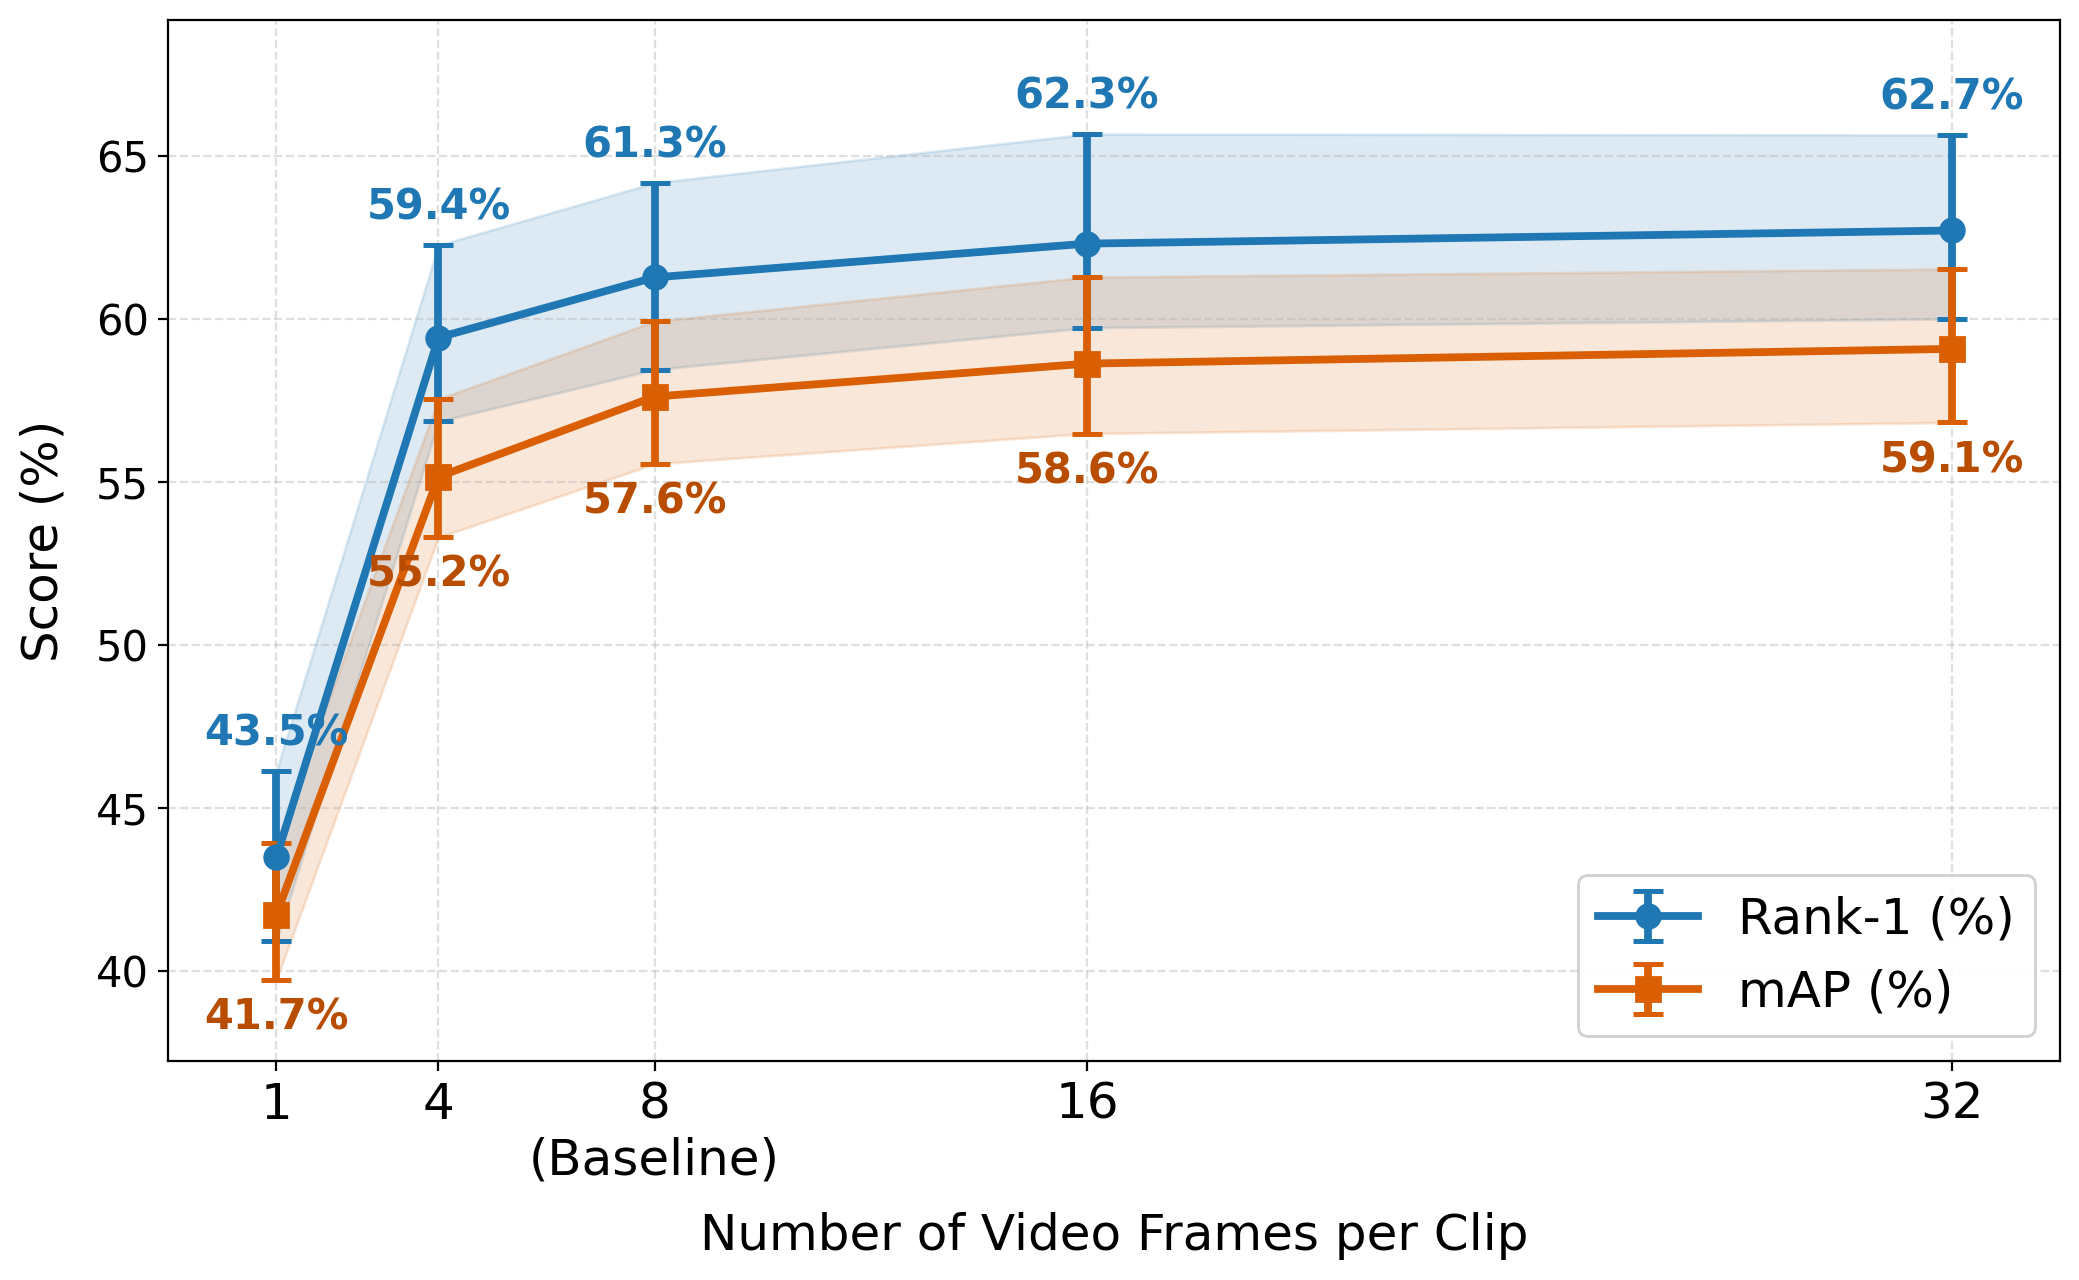

In [11]:
# =====================================================================
# Plot: Performance vs. Number of Frames (with 95% Bootstrap CIs)
# =====================================================================
frame_plot_defs = [
    {"frames": 1, "label": "1", "path": DIAG_DIR / "baseline_vid2vid_len1" / "closed_dist_matrix.csv"},
    {"frames": 4, "label": "4", "path": DIAG_DIR / "baseline_vid2vid_len4" / "closed_dist_matrix.csv"},
    {"frames": 8, "label": "8\n(Baseline)", "path": CLOSED_DIR / "baseline_vid2vid" / "closed_dist_matrix.csv", "is_base": True},
    {"frames": 16, "label": "16", "path": DIAG_DIR / "baseline_vid2vid_len16" / "closed_dist_matrix.csv"},
    {"frames": 32, "label": "32", "path": DIAG_DIR / "baseline_vid2vid_len32" / "closed_dist_matrix.csv"},
    {"frames": 64, "label": "64", "path": DIAG_DIR / "baseline_vid2vid_len64" / "closed_dist_matrix.csv"},
]

plot_frames = []
for fc in frame_plot_defs:
    p = fc["path"]
    if p.exists() and p.stat().st_size > 0:
        res = bootstrap_from_csv(str(p), m=100, mode="closed")
        cmc_boot = res.get("cmc_boot_mean")
        cmc_l = res.get("cmc_ci_lower")
        cmc_u = res.get("cmc_ci_upper")
        r1 = cmc_boot[0] * 100
        r1_l, r1_u = cmc_l[0] * 100, cmc_u[0] * 100
        
        m_mean = res.get("mAP_boot_mean") * 100
        m_ci = res.get("mAP_ci")
        m_l, m_u = m_ci[0] * 100, m_ci[1] * 100
        
        plot_frames.append({
            "frames": fc["frames"],
            "label": fc["label"],
            "is_base": fc.get("is_base", False),
            "r1": r1, "r1_l": r1_l, "r1_u": r1_u,
            "map": m_mean, "map_l": m_l, "map_u": m_u,
        })

if len(plot_frames) >= 2:
    fig, ax = plt.subplots(figsize=(10.5, 6.5), dpi=200)
    x_vals = np.array([s["frames"] for s in plot_frames])
    labels = [s["label"] for s in plot_frames]
    
    r1_vals = np.array([s["r1"] for s in plot_frames])
    r1_lows = np.array([s["r1_l"] for s in plot_frames])
    r1_highs = np.array([s["r1_u"] for s in plot_frames])
    
    map_vals = np.array([s["map"] for s in plot_frames])
    map_lows = np.array([s["map_l"] for s in plot_frames])
    map_highs = np.array([s["map_u"] for s in plot_frames])
    
    # Shaded 95% Confidence Interval bands
    ax.fill_between(x_vals, r1_lows, r1_highs, color="#1f77b4", alpha=0.15, label="_nolegend_")
    ax.fill_between(x_vals, map_lows, map_highs, color="#d95f02", alpha=0.15, label="_nolegend_")
    
    # Curves with error bars (scaled by actual number of frames on x-axis)
    ax.errorbar(x_vals, r1_vals, yerr=[r1_vals - r1_lows, r1_highs - r1_vals],
                fmt="-o", color="#1f77b4", label="Rank-1 (%)",
                linewidth=2.8, markersize=8.5, capsize=5.5, capthick=1.8)
    
    ax.errorbar(x_vals, map_vals, yerr=[map_vals - map_lows, map_highs - map_vals],
                fmt="-s", color="#d95f02", label="mAP (%)",
                linewidth=2.8, markersize=8.5, capsize=5.5, capthick=1.8)
    
    # Annotate points with values in percentage format just outside confidence intervals
    for i, s in enumerate(plot_frames):
        x_pos = s["frames"]
        ax.annotate(
            f"{s['r1']:.1f}%",
            xy=(x_pos, s["r1_u"]),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=15,
            color="#1f77b4",
            weight="bold",
        )

        ax.annotate(
            f"{s['map']:.1f}%",
            xy=(x_pos, s["map_l"]),
            xytext=(0, -6),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=15,
            color="#b84d00",
            weight="bold",
        )
    
    ax.set_xticks(x_vals)
    ax.set_xticklabels(labels, fontsize=18)
    ax.tick_params(axis="y", labelsize=15)
    ax.set_xlabel("Number of Video Frames per Clip", fontsize=18, labelpad=10)
    ax.set_ylabel("Score (%)", fontsize=18, labelpad=10)
    ax.grid(True, linestyle="--", alpha=0.4)
    
    # Linear scale bounds with breathing room
    x_pad = 2 if max(x_vals) <= 32 else 4
    ax.set_xlim(min(x_vals) - 2, max(x_vals) + x_pad)
    
    y_min = max(0.0, min(map_lows) - 2.5)
    y_max = min(100.0, max(r1_highs) + 3.5)
    ax.set_ylim(y_min, y_max)
    
    ax.legend(loc="lower right", framealpha=0.92, fontsize=18)
    plt.tight_layout()
    
    fig_dir = ROOT_DIR / "evaluation" / "figures"
    fig_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(fig_dir / "frame_length_scaling.png", dpi=300, bbox_inches="tight")
    plt.savefig(fig_dir / "frame_length_scaling.pdf", bbox_inches="tight")
    print("-> Saved figure to " + str(fig_dir / "frame_length_scaling.png"))
    plt.show()
else:
    print("[INFO] Insufficient frame counts discovered yet to render curve plot.")

## Feature Pooling & Aggregation Ablation (Temporal & Spatial)


In [13]:
# =====================================================================
# Feature Pooling & Aggregation: Temporal & Spatial Tables
# =====================================================================
ABLATIONS_DIR = ROOT_DIR / "evaluation" / "csvs_ablations"
CLOSED_DIR = ROOT_DIR / "evaluation" / "csvs_closed_results"

def get_pooling_row(name, path, fallback_path=None, ref_r1=None, ref_map=None, desc=""):
    p = path if path.exists() and path.stat().st_size > 0 else (fallback_path if fallback_path and fallback_path.exists() else None)
    if not p:
        return {"Method": name, "Rank-1 (%) [95% CI]": "Pending...", "mAP (%) [95% CI]": "Pending...", "Δ (R-1 / mAP)": "-", "Description": desc}
    res = bootstrap_from_csv(str(p), m=100, mode="closed")
    m_mean = res.get("mAP_boot_mean", 0.0) * 100
    m_std = res.get("mAP_std", 0.0) * 100
    m_ci = res.get("mAP_ci", (0.0, 0.0))
    cmc_boot = res.get("cmc_boot_mean", [0.0]*10)
    cmc_std = res.get("cmc_std", np.zeros(10))
    cmc_l = res.get("cmc_ci_lower", cmc_boot)
    cmc_u = res.get("cmc_ci_upper", cmc_boot)
    cmc = cmc_boot[0] * 100
    r1_std = cmc_std[0] * 100 if len(cmc_std) > 0 else 0.0
    cmc_ci = (cmc_l[0] * 100, cmc_u[0] * 100)
    r5 = cmc_boot[4] * 100 if len(cmc_boot) >= 5 else 0.0
    r5_std = cmc_std[4] * 100 if len(cmc_std) >= 5 else 0.0
    r5_ci = (cmc_l[4] * 100, cmc_u[4] * 100) if len(cmc_l) >= 5 else (r5, r5)
    delta = "Reference" if ref_r1 is None else f"{(cmc - ref_r1):+.1f} / {(m_mean - ref_map):+.1f}"
    return {
        "Method": name,
        "Rank-1 (%) [95% CI]": f"{cmc:.1f} ± {r1_std:.1f} [{cmc_ci[0]:.1f}-{cmc_ci[1]:.1f}]",
        "Rank-5 (%) [95% CI]": f"{r5:.1f} ± {r5_std:.1f} [{r5_ci[0]:.1f}-{r5_ci[1]:.1f}]",
        "mAP (%) [95% CI]": f"{m_mean:.1f} ± {m_std:.1f} [{m_ci[0]*100:.1f}-{m_ci[1]*100:.1f}]",
        "Δ (R-1 / mAP)": delta,
        "Description": desc,
        "_r1": cmc, "_r5": r5, "_map": m_mean
    }

# 1. Temporal Pooling Across Frames
base_temp = get_pooling_row(
    "Temporal Attention Pooling (Baseline)",
    CLOSED_DIR / "baseline_vid2vid" / "closed_dist_matrix.csv",
    ABLATIONS_DIR / "baseline_vid2vid" / "closed_dist_matrix.csv",
    desc="Learnable temporal self-attention across 8 frames"
)
temp_r1, temp_map = base_temp.get("_r1"), base_temp.get("_map")

temporal_rows = [
    base_temp,
    get_pooling_row(
        "Temporal Mean Pooling",
        ABLATIONS_DIR / "temporal_mean_vid2vid" / "closed_dist_matrix.csv",
        ref_r1=temp_r1, ref_map=temp_map,
        desc="Global average pooling across 8 video frames"
    ),
    get_pooling_row(
        "Temporal Max Pooling",
        ABLATIONS_DIR / "temporal_max_vid2vid" / "closed_dist_matrix.csv",
        ref_r1=temp_r1, ref_map=temp_map,
        desc="Element-wise maximum across 8 video frames"
    )
]
df_temporal = pd.DataFrame(temporal_rows)[["Method", "Rank-1 (%) [95% CI]", "Rank-5 (%) [95% CI]", "mAP (%) [95% CI]", "Δ (R-1 / mAP)", "Description"]]

# 2. Spatial Token Pooling Within Frame Backbone
base_spat = get_pooling_row(
    "Pure [CLS] Token (Baseline)",
    CLOSED_DIR / "baseline_vid2vid" / "closed_dist_matrix.csv",
    ABLATIONS_DIR / "baseline_vid2vid" / "closed_dist_matrix.csv",
    desc="Global class token from last transformer block"
)
spat_r1, spat_map = base_spat.get("_r1"), base_spat.get("_map")

spatial_rows = [
    base_spat,
    get_pooling_row(
        "Patch Mean Pooling",
        ABLATIONS_DIR / "patch_mean_vid2vid" / "closed_dist_matrix.csv",
        ref_r1=spat_r1, ref_map=spat_map,
        desc="Global average pooling over spatial patch tokens"
    ),
    get_pooling_row(
        "Patch GeM Pooling",
        ABLATIONS_DIR / "patch_gem_vid2vid" / "closed_dist_matrix.csv",
        ref_r1=spat_r1, ref_map=spat_map,
        desc="Generalized mean pooling (p=3.0) over spatial patches"
    ),
    get_pooling_row(
        "CLS + Patch Mean",
        ABLATIONS_DIR / "cls_mean_vid2vid" / "closed_dist_matrix.csv",
        ref_r1=spat_r1, ref_map=spat_map,
        desc="Concatenation of [CLS] token and spatial patch mean"
    ),
    get_pooling_row(
        "CLS + Patch GeM",
        ABLATIONS_DIR / "cls_gem_vid2vid" / "closed_dist_matrix.csv",
        ref_r1=spat_r1, ref_map=spat_map,
        desc="Concatenation of [CLS] token and spatial patch GeM"
    )
]
df_spatial = pd.DataFrame(spatial_rows)[["Method", "Rank-1 (%) [95% CI]", "Rank-5 (%) [95% CI]", "mAP (%) [95% CI]", "Δ (R-1 / mAP)", "Description"]]

print("=== Temporal Aggregation (Across Video Frames) ===")
display(df_temporal)

print("\n=== Spatial Token Pooling (Within Frame Backbone) ===")
display(df_spatial)


-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
-> [CACHE HIT] Loaded precomputed closed metrics for closed_dist_matrix.csv (from bootstrap_cache_closed_m100_seed42.pkl)
=== Temporal Aggregation

,Method,Rank-1 (%) [95% CI],Rank-5 (%) [95% CI],mAP (%) [95% CI],Δ (R-1 / mAP),Description
0,Temporal Attention Pooling (Baseline),61.3 ± 1.5 [58.5-64.2],79.6 ± 1.2 [77.2-81.7],57.6 ± 1.1 [55.6-59.9],Reference,Learnable temporal self-attention across 8 frames
1,Temporal Mean Pooling,57.4 ± 1.4 [55.0-59.8],77.0 ± 1.3 [74.9-79.9],53.6 ± 1.1 [51.7-55.7],-3.9 / -4.1,Global average pooling across 8 video frames
2,Temporal Max Pooling,48.4 ± 1.5 [45.8-51.3],69.9 ± 1.3 [67.4-72.9],45.9 ± 1.1 [43.9-48.7],-12.9 / -11.7,Element-wise maximum across 8 video frames


,Method,Rank-1 (%) [95% CI],Rank-5 (%) [95% CI],mAP (%) [95% CI],Δ (R-1 / mAP),Description
0,Pure [CLS] Token (Baseline),61.3 ± 1.5 [58.5-64.2],79.6 ± 1.2 [77.2-81.7],57.6 ± 1.1 [55.6-59.9],Reference,Global class token from last transformer block
1,Patch Mean Pooling,58.6 ± 1.5 [55.5-61.3],77.2 ± 1.2 [74.8-79.6],55.5 ± 1.1 [53.5-57.9],-2.7 / -2.1,Global average pooling over spatial patch tokens
2,Patch GeM Pooling,57.7 ± 1.5 [54.8-60.6],75.7 ± 1.4 [73.4-78.3],54.1 ± 1.2 [51.9-56.5],-3.6 / -3.5,Generalized mean pooling (p=3.0) over spatial patches
3,CLS + Patch Mean,61.7 ± 1.5 [59.2-64.2],79.6 ± 1.2 [77.4-81.7],58.1 ± 1.1 [56.0-60.4],+0.4 / +0.5,Concatenation of [CLS] token and spatial patch mean
4,CLS + Patch GeM,60.6 ± 1.5 [58.0-63.4],80.2 ± 1.2 [77.8-82.4],57.6 ± 1.1 [55.6-59.8],-0.7 / -0.0,Concatenation of [CLS] token and spatial patch GeM


## Gallery Size Sensitivity Analysis (DINOv2 Baseline)

To evaluate how retrieval performance scales with gallery size while guaranteeing that every gallery identity remains retrievable:
- **Queries**: Fixed across all experiments (`1,677` query videos across `680` unique dog identities).
- **Minimum Gallery Baseline (`38.9%` / `777` videos)**: Exactly **1 randomly selected video per gallery identity** (`777` unique gallery identities: `680` matching query identities + `97` distractor identities).
- **Progressive Gallery Scaling (`50.0%`, `62.5%`, `75.0%`, `87.5%`, `100.0%`)**: Randomly sample additional videos from the remaining `1,221` multi-instance gallery videos (`20%`, `40%`, `60%`, `80%`, `100%` of the extra pool) across $m=100$ bootstrap iterations.

In [14]:
# =====================================================================
# 3. Gallery Size Sensitivity Analysis (Option B: Total Gallery %)
# =====================================================================
import pickle
from evaluation_utils import _calc_closed_logic

gallery_steps = [
    {"pct": 38.9, "label": "38.9% (1 vid/ID)", "tick": "38.9%\n(777)", "n_vids": 777, "is_min": True},
    {"pct": 50.0, "label": "50.0%", "tick": "50.0%\n(999)", "n_vids": 999},
    {"pct": 62.5, "label": "62.5%", "tick": "62.5%\n(1,249)", "n_vids": 1249},
    {"pct": 75.0, "label": "75.0%", "tick": "75.0%\n(1,498)", "n_vids": 1498},
    {"pct": 87.5, "label": "87.5%", "tick": "87.5%\n(1,748)", "n_vids": 1748},
    {"pct": 100.0, "label": "100.0% (Full)", "tick": "100.0%\n(1,998)", "n_vids": 1998, "is_ref": True},
]

gal_csv_path = CLOSED_DIR / "baseline_vid2vid" / "closed_dist_matrix.csv"
gal_cache_path = CLOSED_DIR / "baseline_vid2vid" / "gallery_sensitivity_cache_m100_seed42.pkl"

if gal_cache_path.exists():
    with open(gal_cache_path, "rb") as f:
        gallery_summary_stats = pickle.load(f)
else:
    df_full_gal = pd.read_csv(gal_csv_path)
    get_id_fn = lambda x: str(x).rsplit("_", 1)[0]
    q_ids_gal = np.array([get_id_fn(i) for i in df_full_gal["queryId"].values])
    g_ids_gal = np.array([get_id_fn(i) for i in df_full_gal.columns[1:].values])
    dist_mat_gal = df_full_gal.iloc[:, 1:].values.astype(np.float32)

    unique_q_ids = np.unique(q_ids_gal)
    unique_g_ids = np.unique(g_ids_gal)
    q_id_to_indices = {qid: np.where(q_ids_gal == qid)[0] for qid in unique_q_ids}
    g_id_to_indices = {gid: np.where(g_ids_gal == gid)[0] for gid in unique_g_ids}

    rng_q = np.random.default_rng(42)
    rng_g = np.random.default_rng(1042)
    results_gal = {s["pct"]: {"r1": [], "r5": [], "map": []} for s in gallery_steps}

    for _ in range(100):
        sampled_q_dogs = rng_q.choice(unique_q_ids, size=len(unique_q_ids), replace=True)
        q_idx_arr = np.concatenate([q_id_to_indices[qid] for qid in sampled_q_dogs])
        q_pids_arr = q_ids_gal[q_idx_arr]

        mandatory_g_idx, extra_pool_idx = [], []
        for gid in unique_g_ids:
            g_idxs = g_id_to_indices[gid]
            chosen_pos = rng_g.integers(0, len(g_idxs))
            mandatory_g_idx.append(g_idxs[chosen_pos])
            if len(g_idxs) > 1:
                for pos, gx in enumerate(g_idxs):
                    if pos != chosen_pos:
                        extra_pool_idx.append(gx)
        mandatory_g_idx = np.array(mandatory_g_idx)
        perm_extra = rng_g.permutation(np.array(extra_pool_idx))

        for s in gallery_steps:
            pct = s["pct"]
            n_extra = s["n_vids"] - len(mandatory_g_idx)
            g_sub_idx = mandatory_g_idx if n_extra <= 0 else np.concatenate([mandatory_g_idx, perm_extra[:n_extra]])
            sub_dist = dist_mat_gal[np.ix_(q_idx_arr, g_sub_idx)]
            g_sub_pids = g_ids_gal[g_sub_idx]
            match_matrix = q_pids_arr[:, None] == g_sub_pids[None, :]
            sorted_matches = np.take_along_axis(match_matrix, np.argsort(sub_dist, axis=1), axis=1)
            res_g = _calc_closed_logic(sorted_matches)
            results_gal[pct]["r1"].append(res_g["cmc"][0] * 100.0)
            results_gal[pct]["r5"].append(res_g["cmc"][4] * 100.0)
            results_gal[pct]["map"].append(res_g["mAP"] * 100.0)

    gallery_summary_stats = {}
    for s in gallery_steps:
        pct = s["pct"]
        r1_a, r5_a, map_a = np.array(results_gal[pct]["r1"]), np.array(results_gal[pct]["r5"]), np.array(results_gal[pct]["map"])
        gallery_summary_stats[pct] = {
            "r1_mean": float(np.mean(r1_a)), "r1_std": float(np.std(r1_a)), "r1_l": float(np.percentile(r1_a, 2.5)), "r1_u": float(np.percentile(r1_a, 97.5)),
            "r5_mean": float(np.mean(r5_a)), "r5_std": float(np.std(r5_a)), "r5_l": float(np.percentile(r5_a, 2.5)), "r5_u": float(np.percentile(r5_a, 97.5)),
            "map_mean": float(np.mean(map_a)), "map_std": float(np.std(map_a)), "map_l": float(np.percentile(map_a, 2.5)), "map_u": float(np.percentile(map_a, 97.5)),
        }
    with open(gal_cache_path, "wb") as f:
        pickle.dump(gallery_summary_stats, f)

ref_gal_r1 = gallery_summary_stats[100.0]["r1_mean"]
ref_gal_map = gallery_summary_stats[100.0]["map_mean"]
gallery_rows = []
for s in gallery_steps:
    pct = s["pct"]
    st = gallery_summary_stats[pct]
    r1_str = f"{st['r1_mean']:.1f} ± {st['r1_std']:.1f} [{st['r1_l']:.1f}-{st['r1_u']:.1f}]%"
    r5_str = f"{st['r5_mean']:.1f} ± {st['r5_std']:.1f} [{st['r5_l']:.1f}-{st['r5_u']:.1f}]%"
    map_str = f"{st['map_mean']:.1f} ± {st['map_std']:.1f} [{st['map_l']:.1f}-{st['map_u']:.1f}]%"
    delta_str = "Reference" if s.get("is_ref") else f"{st['r1_mean'] - ref_gal_r1:+.1f}% / {st['map_mean'] - ref_gal_map:+.1f}%"
    gallery_rows.append({
        "Gallery Size (%)": s["label"],
        "Gallery Videos": f"{s['n_vids']:,}",
        "Rank-1 (%) [95% CI]": r1_str,
        "Rank-5 (%) [95% CI]": r5_str,
        "mAP (%) [95% CI]": map_str,
        "Δ (R-1 / mAP)": delta_str,
    })

df_gallery = pd.DataFrame(gallery_rows)
print("\n=== Gallery Size Sensitivity Analysis (DINOv2 Baseline) ===")
display(df_gallery)



=== Gallery Size Sensitivity Analysis (DINOv2 Baseline) ===


Gallery Size (%),Gallery Videos,Rank-1 (%) [95% CI],Rank-5 (%) [95% CI],mAP (%) [95% CI],Δ (R-1 / mAP)
38.9% (1 vid/ID),777,51.6 ± 1.6 [49.1-54.9]%,77.2 ± 1.5 [75.0-80.0]%,62.9 ± 1.3 [60.7-65.6]%,-9.7% / +5.3%
50.0%,999,53.6 ± 1.8 [50.8-57.7]%,76.5 ± 1.5 [73.6-79.6]%,61.4 ± 1.3 [59.2-64.0]%,-7.6% / +3.8%
62.5%,"1,249",55.9 ± 1.8 [52.8-60.0]%,76.7 ± 1.4 [74.0-79.7]%,60.1 ± 1.3 [58.0-62.5]%,-5.4% / +2.4%
75.0%,"1,498",57.8 ± 1.9 [54.8-61.5]%,77.4 ± 1.5 [74.9-80.3]%,59.0 ± 1.3 [56.9-61.5]%,-3.4% / +1.4%
87.5%,"1,748",59.7 ± 1.7 [56.5-62.8]%,78.4 ± 1.4 [75.9-80.9]%,58.2 ± 1.2 [56.0-60.6]%,-1.6% / +0.6%
100.0% (Full),"1,998",61.3 ± 1.5 [58.5-64.2]%,79.6 ± 1.2 [77.2-81.7]%,57.6 ± 1.1 [55.6-59.9]%,Reference


-> Saved figure to /d/hpc/projects/FRI/mm12755/DogReID-1553/DogReID-1553/evaluation/figures/gallery_size_scaling.png


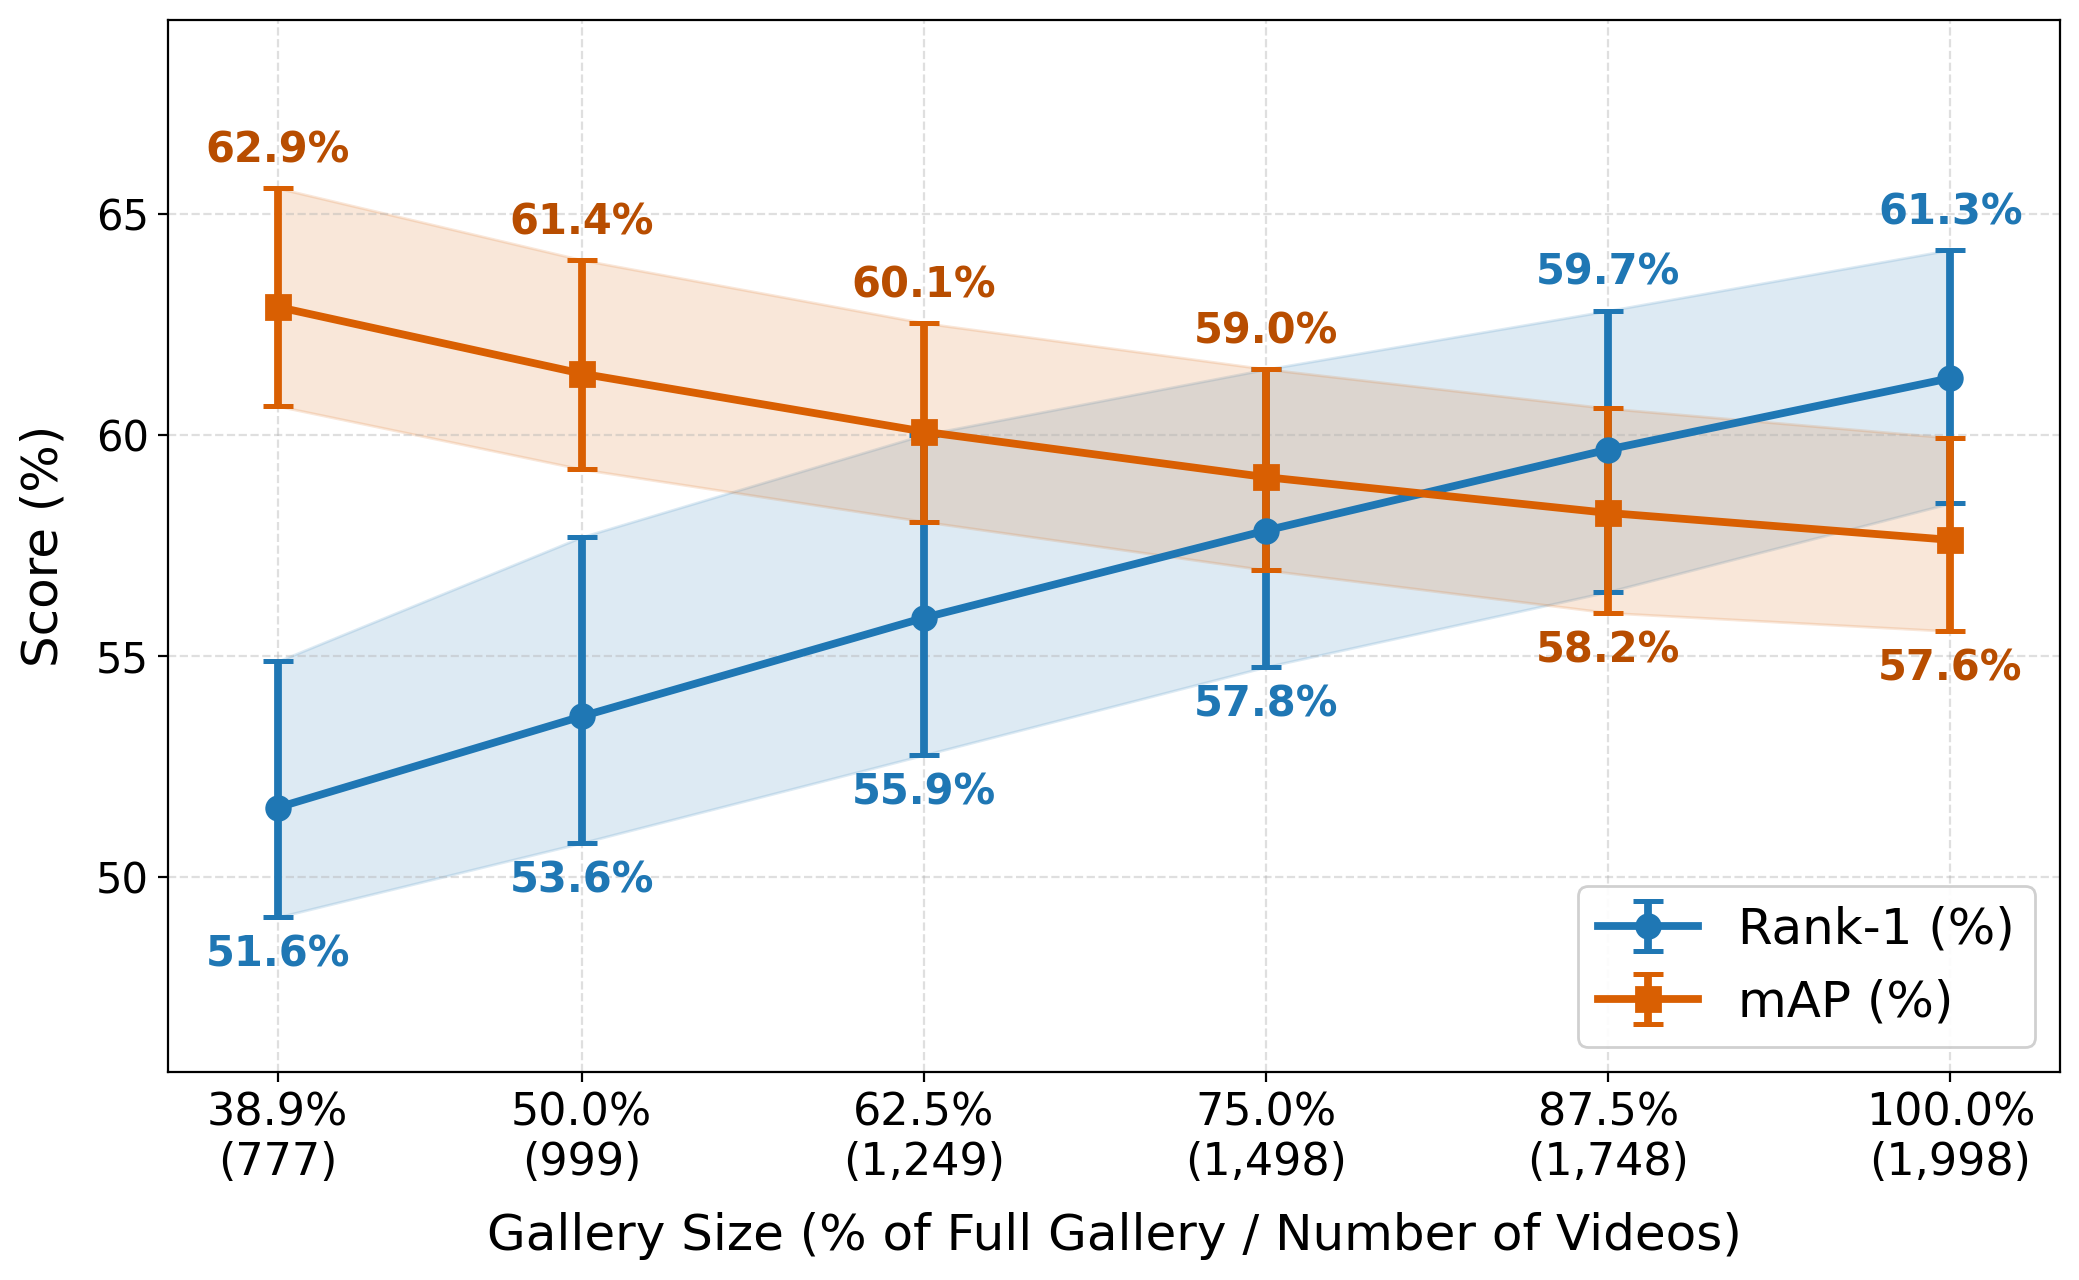

In [15]:
# =====================================================================
# Plot: Gallery Size Sensitivity (Rank-1 & mAP vs. Gallery Size %)
# =====================================================================
fig, ax = plt.subplots(figsize=(10.5, 6.5), dpi=200)
x_vals = np.array([s["pct"] for s in gallery_steps])
labels = [s["tick"] for s in gallery_steps]

r1_vals = np.array([gallery_summary_stats[s["pct"]]["r1_mean"] for s in gallery_steps])
r1_lows = np.array([gallery_summary_stats[s["pct"]]["r1_l"] for s in gallery_steps])
r1_highs = np.array([gallery_summary_stats[s["pct"]]["r1_u"] for s in gallery_steps])

map_vals = np.array([gallery_summary_stats[s["pct"]]["map_mean"] for s in gallery_steps])
map_lows = np.array([gallery_summary_stats[s["pct"]]["map_l"] for s in gallery_steps])
map_highs = np.array([gallery_summary_stats[s["pct"]]["map_u"] for s in gallery_steps])

# Shaded 95% Confidence Interval bands
ax.fill_between(x_vals, r1_lows, r1_highs, color="#1f77b4", alpha=0.15, label="_nolegend_")
ax.fill_between(x_vals, map_lows, map_highs, color="#d95f02", alpha=0.15, label="_nolegend_")

# Curves with error bars (linearly scaled by actual gallery percentage on x-axis)
ax.errorbar(x_vals, r1_vals, yerr=[r1_vals - r1_lows, r1_highs - r1_vals],
            fmt="-o", color="#1f77b4", label="Rank-1 (%)",
            linewidth=2.8, markersize=8.5, capsize=5.5, capthick=1.8)

ax.errorbar(x_vals, map_vals, yerr=[map_vals - map_lows, map_highs - map_vals],
            fmt="-s", color="#d95f02", label="mAP (%)",
            linewidth=2.8, markersize=8.5, capsize=5.5, capthick=1.8)

# Annotate points outside confidence intervals (automatically placing higher metric above and lower below)
for s in gallery_steps:
    pct = s["pct"]
    st = gallery_summary_stats[pct]
    x_pos = pct
    if st["r1_mean"] >= st["map_mean"]:
        ax.annotate(f"{st['r1_mean']:.1f}%", xy=(x_pos, st["r1_u"]), xytext=(0, 6),
                    textcoords="offset points", ha="center", va="bottom", fontsize=15, color="#1f77b4", weight="bold")
        ax.annotate(f"{st['map_mean']:.1f}%", xy=(x_pos, st["map_l"]), xytext=(0, -6),
                    textcoords="offset points", ha="center", va="top", fontsize=15, color="#b84d00", weight="bold")
    else:
        ax.annotate(f"{st['map_mean']:.1f}%", xy=(x_pos, st["map_u"]), xytext=(0, 6),
                    textcoords="offset points", ha="center", va="bottom", fontsize=15, color="#b84d00", weight="bold")
        ax.annotate(f"{st['r1_mean']:.1f}%", xy=(x_pos, st["r1_l"]), xytext=(0, -6),
                    textcoords="offset points", ha="center", va="top", fontsize=15, color="#1f77b4", weight="bold")

ax.set_xticks(x_vals)
ax.set_xticklabels(labels, fontsize=16)
ax.tick_params(axis="y", labelsize=15)
ax.set_xlabel("Gallery Size (% of Full Gallery / Number of Videos)", fontsize=18, labelpad=10)
ax.set_ylabel("Score (%)", fontsize=18, labelpad=10)
ax.grid(True, linestyle="--", alpha=0.4)

ax.set_xlim(min(x_vals) - 4.0, max(x_vals) + 4.0)
y_min = max(0.0, min(min(r1_lows), min(map_lows)) - 3.5)
y_max = min(100.0, max(max(r1_highs), max(map_highs)) + 3.8)
ax.set_ylim(y_min, y_max)

ax.legend(loc="lower right", framealpha=0.92, fontsize=18)
plt.tight_layout()

fig_dir = ROOT_DIR / "evaluation" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_dir / "gallery_size_scaling.png", dpi=300, bbox_inches="tight")
plt.savefig(fig_dir / "gallery_size_scaling.pdf", bbox_inches="tight")
print("-> Saved figure to " + str(fig_dir / "gallery_size_scaling.png"))
plt.show()
